# Lab 1 · Notebook 2 — Under the hood: tokens → tensors → logits ⏱ ~30 min

In Notebook 1 a pipeline looked like magic. Here you rebuild it by hand, in the same three stages from the slides:

**preprocess** (`AutoTokenizer`) → **forward** (`AutoModelFor<TASK>`) → **postprocess** (softmax + `id2label`).

You will also see that the *same BERT-style body* can give you **embeddings** (for search) and **masked-word predictions**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import torch, pandas as pd
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          AutoModelForMaskedLM, pipeline)

SENT_MODEL = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
FILL_MODEL = "distilbert/distilbert-base-uncased"
EMB_MODEL  = "sentence-transformers/all-MiniLM-L6-v2"   # a small BERT-style encoder trained to produce sentence embeddings
torch.manual_seed(0)

W1022 21:49:38.239000 54496 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1 · The tokenizer: text → integers
A model never sees letters. The tokenizer cuts text into **sub-word tokens** from a fixed vocabulary and maps each to an integer id.

In [2]:
tok = AutoTokenizer.from_pretrained(SENT_MODEL)
text = "Transformers are unbelievably useful!"

enc = tok(text, return_tensors="pt")             # "pt" = PyTorch tensors
print(enc, "\n")
print(tok.convert_ids_to_tokens(enc["input_ids"][0]))
print("vocabulary size:", tok.vocab_size)

{'input_ids': tensor([[  101, 19081,  2024,  4895,  8671,  2666,  3567,  6321,  6179,   999,
           102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])} 

['[CLS]', 'transformers', 'are', 'un', '##bel', '##ie', '##va', '##bly', 'useful', '!', '[SEP]']
vocabulary size: 30522


Things to notice: `[CLS]` and `[SEP]` are **special tokens** added around the text; a long or rare word is split into pieces
(`##` means “continues the previous piece”); `attention_mask` is all 1s because there is no padding yet.

When we process several texts at once, shorter ones are **padded** so they form a rectangle, and `attention_mask` marks the padding with 0:

In [3]:
batch = tok(["Short one.", "A noticeably longer sentence goes here, with more words."], padding=True, return_tensors="pt")
print(batch["input_ids"].shape)
print(batch["attention_mask"])

torch.Size([2, 13])
tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


### 🔨 TODO 4 — how expensive is your language? (4 min)
Models are billed and limited **per token**, not per word. Write `token_stats(text)` returning the number of words
(split on spaces), the number of tokens (*without* special tokens) and the ratio.

In [4]:
def token_stats(text):
    words = text.split()
    tokens = tok.tokenize(text)                      # no [CLS]/[SEP] added by tokenize()
    return {"words": len(words), "tokens": len(tokens),
            "tokens_per_word": round(len(tokens) / max(len(words), 1), 2)}

In [5]:
assert token_stats("hello world") == {"words": 2, "tokens": 2, "tokens_per_word": 1.0}
print("✅ TODO 4 passed\n")

samples = {
    "English":  "The weather is lovely today and we are going to the park.",
    "French":   "Il fait très beau aujourd'hui et nous allons au parc.",
    "German":   "Donaudampfschifffahrtsgesellschaft",
    "Code":     "def add(a, b): return a + b",
    "Emoji":    "I love it 😍😍😍",
}
pd.DataFrame({k: token_stats(v) for k, v in samples.items()}).T.astype({"words": int, "tokens": int})

✅ TODO 4 passed



,words,tokens,tokens_per_word
English,12,13,1.08
French,10,18,1.80
German,1,12,12.00
Code,7,12,1.71
Emoji,4,4,1.00


**Discuss:** which text needs the most tokens per word, and what does that mean for *cost* and for the model's *context window* in a multilingual product?

## 2 · The model: integers → logits
`AutoModelForSequenceClassification` = BERT-style body + a small **classification head** (the “task head” from the slides).

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(SENT_MODEL).eval()   # .eval() turns dropout off

cfg = model.config
n_params = sum(p.numel() for p in model.parameters())
print(f"layers={cfg.num_hidden_layers}  heads={cfg.num_attention_heads}  hidden size={cfg.hidden_size}  parameters={n_params/1e6:.0f}M")
print("labels:", cfg.id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 10211.09it/s]

layers=6  heads=12  hidden size=768  parameters=67M
labels: {0: 'NEGATIVE', 1: 'POSITIVE'}


In [7]:
enc = tok("I absolutely loved this film!", return_tensors="pt")
with torch.no_grad():                      # no gradients needed for inference
    out = model(**enc)

print("logits:", out.logits)               # raw scores, one per label
probs = torch.softmax(out.logits, dim=-1)  # turn scores into probabilities that sum to 1
print("probs :", probs)
print("answer:", model.config.id2label[int(probs.argmax())])

logits: tensor([[-4.3397,  4.6802]])
probs : tensor([[1.2097e-04, 9.9988e-01]])
answer: POSITIVE


### 🔨 TODO 5 — rebuild the pipeline (6 min)
Write `predict_proba(texts)`: take a **list** of texts, tokenize them with padding, run the model, apply softmax and return
a list of dicts like `{"NEGATIVE": 0.01, "POSITIVE": 0.99}`. Then the self-check compares you with the official pipeline.

In [8]:
def predict_proba(texts):
    batch = tok(texts, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        logits = model(**batch).logits
    probs = torch.softmax(logits, dim=-1)
    return [{model.config.id2label[i]: p.item() for i, p in enumerate(row)} for row in probs]

In [9]:
test_texts = ["I loved it!", "Worst purchase ever, total waste of money.", "Not bad."]
official = pipeline("sentiment-analysis", model=SENT_MODEL, device=-1, top_k=None)(test_texts)   # device=-1: stay on CPU
mine = predict_proba(test_texts)
for m, o in zip(mine, official):
    o = {d["label"]: d["score"] for d in o}
    assert abs(m["POSITIVE"] - o["POSITIVE"]) < 1e-3, (m, o)
print("✅ TODO 5 passed — your hand-made pipeline matches Hugging Face's")
pd.DataFrame(mine, index=test_texts).round(4)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 13709.46it/s]

✅ TODO 5 passed — your hand-made pipeline matches Hugging Face's


,NEGATIVE,POSITIVE
I loved it!,0.0001,0.9999
"Worst purchase ever, total waste of money.",0.9998,0.0002
Not bad.,0.0005,0.9995


## 3 · The same body gives *embeddings* — the seed of semantic search
If we drop the task head and keep the body (`AutoModel`), we get one vector **per token**: `last_hidden_state`.
Averaging them (ignoring padding) gives **one vector per sentence**. Sentences with similar *meaning* land close together.

In [10]:
tok_e = AutoTokenizer.from_pretrained(EMB_MODEL)
enc_model = AutoModel.from_pretrained(EMB_MODEL).eval()

def embed(texts):
    """texts -> tensor (n, 384) of unit-length sentence embeddings (mean pooling)."""
    batch = tok_e(texts, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        hidden = enc_model(**batch).last_hidden_state           # (n, seq_len, 384): one vector per token
    mask = batch["attention_mask"].unsqueeze(-1)                  # ignore padding when averaging
    pooled = (hidden * mask).sum(1) / mask.sum(1)
    return torch.nn.functional.normalize(pooled, dim=-1)          # unit length -> dot product = cosine similarity

e = embed(["A cat sits on the mat.", "A kitten is resting on a rug.", "Stock markets fell sharply on Monday."])
print("embedding shape:", tuple(e.shape))
print("cat vs kitten :", round((e[0] @ e[1]).item(), 3))
print("cat vs stocks :", round((e[0] @ e[2]).item(), 3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7950.04it/s]

embedding shape: (3, 384)
cat vs kitten : 0.655
cat vs stocks : 0.031


### 🔨 TODO 6 — a 5-line search engine (5 min)
Write `semantic_search(query, corpus, k=3)` returning the `k` most similar corpus sentences as `(sentence, score)` pairs, best first.

In [11]:
def semantic_search(query, corpus, k=3):
    q, c = embed([query]), embed(corpus)
    scores = (q @ c.T)[0]                          # cosine similarity with every corpus sentence
    top = scores.topk(min(k, len(corpus)))
    return [(corpus[i], round(s.item(), 3)) for s, i in zip(top.values, top.indices)]

In [12]:
faq = [
    "You can reset your password from the login page by clicking 'Forgot password'.",
    "Our office is open Monday to Friday from 9am to 5pm.",
    "Refunds are issued to the original payment method within 5 working days.",
    "To change your delivery address, edit it in your account settings before the order ships.",
    "We offer student discounts with a valid university email address.",
    "The mobile app is available for both iOS and Android.",
    "Contact support by email or through the chat widget in the bottom corner.",
    "Your subscription renews automatically at the end of each billing period.",
]
hits = semantic_search("I forgot my login credentials", faq, k=3)
assert "password" in hits[0][0], hits
print("✅ TODO 6 passed\n")
for sentence, score in semantic_search("When will I get my money back?", faq, k=3):
    print(f"{score:.3f}  {sentence}")

✅ TODO 6 passed

0.547  Refunds are issued to the original payment method within 5 working days.
0.279  Your subscription renews automatically at the end of each billing period.
0.162  Contact support by email or through the chat widget in the bottom corner.


Notice the query shares almost **no words** with the best answer — that is the difference between *semantic* and *keyword* search,
and it is the retrieval half of the RAG systems you will meet later in the course.

## 4 · The masked-language-model head: how BERT was pre-trained
`AutoModelForMaskedLM` puts a different head on the same kind of body: it scores **every vocabulary word** for each position.
Find the `[MASK]` position, read its logits, take the top-k.

In [13]:
tok_m = AutoTokenizer.from_pretrained(FILL_MODEL)
mlm = AutoModelForMaskedLM.from_pretrained(FILL_MODEL).eval()

def top_masked(text, k=5):
    batch = tok_m(text, return_tensors="pt")
    pos = (batch["input_ids"][0] == tok_m.mask_token_id).nonzero()[0].item()    # index of the first [MASK]
    with torch.no_grad():
        logits = mlm(**batch).logits[0, pos]                                   # scores over the whole vocabulary
    probs = logits.softmax(-1)
    top = probs.topk(k)
    return [(tok_m.decode(int(i)), round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

top_masked("The capital of France is [MASK].")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 8764.57it/s]

[('marseille', 0.143),
 ('nantes', 0.09),
 ('toulouse', 0.088),
 ('paris', 0.086),
 ('lyon', 0.077)]

**Surprised?** The right answer is not first. A masked language model predicts the words that *fit the context statistically*;
it is **not looking facts up**. Keep this in mind when we reach large generative models and talk about hallucination.
(Compare with Notebook 1, where "Paris is the [MASK] of France." gave *capital* 98 %.)

### 🔍 Mini-investigation — what did the model learn about the world? (3 min)
BERT learned from human-written text, so it also learned our **stereotypes**. Run the probes, then write down what you see.

In [14]:
prompts = [
    "The nurse said that [MASK] was tired after the long shift.",
    "The engineer said that [MASK] was tired after the long shift.",
    "The [MASK] cooked dinner while the man worked late.",
]
for p in prompts:
    print(p, "\n   ->", top_masked(p, k=4))

The nurse said that [MASK] was tired after the long shift. 
   -> [('she', 0.139), ('he', 0.041), ('everyone', 0.013), ('i', 0.005)]
The engineer said that [MASK] was tired after the long shift. 
   -> [('he', 0.094), ('she', 0.029), ('everyone', 0.01), ('nobody', 0.008)]
The [MASK] cooked dinner while the man worked late. 
   -> [('waitress', 0.118), ('chef', 0.081), ('woman', 0.073), ('cook', 0.041)]


_Your observation (2 sentences). Could this matter in an HR or hiring application?_

---
### ⭐ Bonus (if you finish early): look at attention
The attention matrix from the slides is not a diagram — you can extract it.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 15337.02it/s]

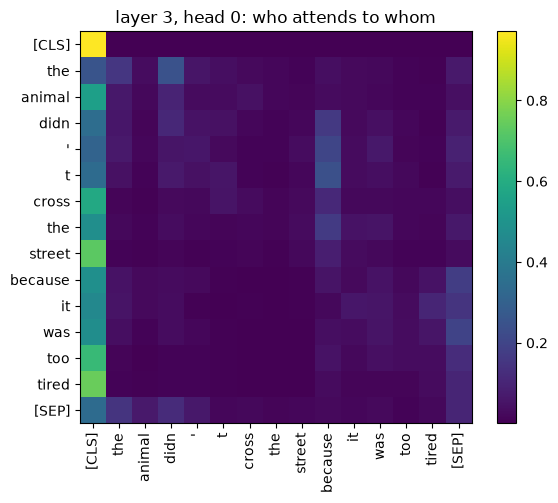

In [15]:
import matplotlib.pyplot as plt
eager = AutoModel.from_pretrained(EMB_MODEL, attn_implementation="eager").eval()   # "eager" attention can return the weights
sentence = "The animal didn't cross the street because it was too tired"
b = tok_e(sentence, return_tensors="pt")
with torch.no_grad():
    att = eager(**b, output_attentions=True).attentions        # tuple: one tensor per layer, shape (1, heads, seq, seq)
toks = tok_e.convert_ids_to_tokens(b["input_ids"][0])
layer, head = 3, 0                                              # change these and look for different patterns!
plt.figure(figsize=(6, 5)); plt.imshow(att[layer][0, head], cmap="viridis")
plt.xticks(range(len(toks)), toks, rotation=90); plt.yticks(range(len(toks)), toks)
plt.title(f"layer {layer}, head {head}: who attends to whom"); plt.colorbar(); plt.tight_layout(); plt.show()

## ✅ Checkpoint — you should now be able to say
* what `input_ids` and `attention_mask` are, and why padding exists;
* why a text in one language can cost 2–3× more tokens than another;
* the path **logits → softmax → id2label**, and that a pipeline is exactly that;
* how the *same* encoder body serves classification, embeddings and masked-word prediction by swapping the **head**.

**Next:** Notebook 3 — wrap these functions in a web interface with Gradio.